## Preliminaries

Freeze backbone from ResNet trained in `ResNet_Train.ipynb` and transform concept images in the latent space of the CNN.

The explanation will then be formulated on the basis of the $k$ nearest concepts.

In [1]:
!pwd
import sys, os
sys.path.append('./wingbeats/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import glob
import time
import shutil
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd
import plotly.express as px
from tensorflow.keras.layers.experimental.preprocessing import Rescaling

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2023-04-21 12:19:46.423909: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-04-21 12:19:47.019339: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47187 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
spec_subfolder = '5_species/'
metafolder = './beexplainable/metafiles/CUB/bbox/'
CONCEPTS_PATH = '../data/CUB_5spec/Concepts_StabDiff/'

CLASSES_PATH = metafolder + spec_subfolder + 'classes.txt'
BIRDS_PATH = '../data/CUB_5spec/images/'

IMAGES_PATH = metafolder + spec_subfolder + 'images.txt'
IMAGES_LABELS_PATH = metafolder + spec_subfolder + 'image_class_labels.txt'

MODELS_PATH  = './beexplainable/models/'
FIGURES_PATH = './beexplainable/figures/concepts/'

## Load Images

In [5]:
batch_size = 64
img_height = img_width = 224

### Validation Set Bee Images

In [6]:
# Read file IDs and corresponding class labels
img_dict = mr.metafile_to_dict(IMAGES_PATH)
img_label_dict = mr.metafile_to_dict(IMAGES_LABELS_PATH)
file_ids_bees = list( img_dict.keys() )
y_true_bees   = list( img_label_dict.values() )
y_true_bees   = np.asarray(y_true_bees, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
len(y_true_bees)

295

In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Laysan_Albatross',
 'Cardinal',
 'Eastern_Towhee',
 'Red_bellied_Woodpecker',
 'Red_cockaded_Woodpecker']

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_bees, list(img_dict.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, BIRDS_PATH),
                                          label)

2023-04-21 12:19:47.091891: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47187 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
train_val_set = ps.parse_to_dataset(file_ids_bees, y_true_bees, parse_image_lab)
train_val_set = train_val_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_val_set = train_val_set.map(lambda x, y: (normalization_layer(x), y))

2023-04-21 12:19:48.243195: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


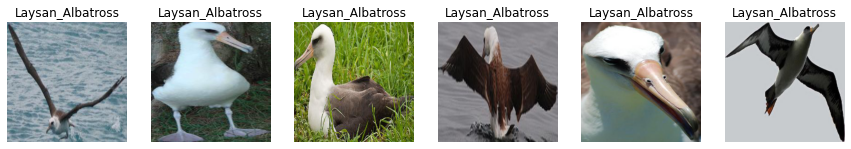

In [10]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in train_val_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(classes[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [11]:
for image_batch, labels_batch in train_val_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=uint8)


2023-04-21 12:19:48.983716: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


### Concept Images

In [12]:
# Store concepts, image paths and create label vector from subfolder names
concepts, concept_files, y_true_con = [], [], []
concept_subfolders = sorted( glob.glob(CONCEPTS_PATH + '*') )
for i in range(len(concept_subfolders)):
    # Add concept from subfolder base name
    concept = os.path.basename(concept_subfolders[i])
    concepts.append( concept )

    # Get image paths in current concept subfolder (there are .jpg and .png files)
    c_files = glob.glob(CONCEPTS_PATH + concept + '/*.jpg') + glob.glob(CONCEPTS_PATH + concept + '/*.png')
    concept_files += [c[len(CONCEPTS_PATH):] for c in c_files] # remove the constant path to the common dir.
    y_true_con += [i] * len(c_files)

In [13]:
concepts

['flat_black_white', 'parallel_black_white', 'red']

In [14]:
# Define file ids (for consistency with the parsers in the pipeline)
# Note: the metafile readers return a Dict[str, str]
file_ids_con = [str(i) for i in range(1, len(y_true_con)+1)]

In [15]:
# Get dictionary of file IDs and file names
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_con, concept_files),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, CONCEPTS_PATH),
                                          label)

In [16]:
# Conversion to tf.Dataset
concept_set = ps.parse_to_dataset(file_ids_con, y_true_con, parse_image_lab)
concept_set = concept_set.cache().batch(batch_size).prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
concept_set = concept_set.map(lambda x, y: (normalization_layer(x), y))

2023-04-21 12:19:50.365138: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


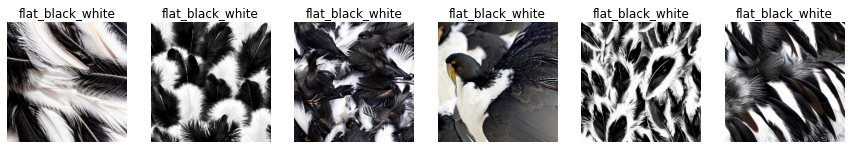

In [17]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = min(6, batch_size)
with tf.device('/CPU:0'):
    for images, labels in concept_set.take(1):
        for i in range(num_cols):
            plt.subplot(1, num_cols, i + 1)
            plt.imshow(images[i])
            plt.title(concepts[labels[i].numpy()])
            plt.axis("off")
plt.show()

In [18]:
for image_batch, labels_batch in concept_set.take(1):
    print(image_batch.shape)
    print(labels_batch[0])

(64, 224, 224, 3)
tf.Tensor(0, shape=(), dtype=int32)


2023-04-21 12:19:51.006229: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


Mapping relevant concepts to true class labels

In [19]:
# One-hot-encode the concepts
enc = OneHotEncoder().fit([[0], [1], [2]])
concept_basis = enc.transform([[0], [1], [2]]).toarray()
# flat_bw     = 100
# parallel_bw = 010
# red         = 001

In [20]:
# Albatross: flat_bw       | Rb Woodpecker: parallel_bw + red
# Cardinal:  red           | Rc Woodpecker: parallel_bw
# Towhee:    flat_bw + red
lookup_cls_concepts = [concept_basis[0],
                       concept_basis[2],
                       concept_basis[0] + concept_basis[2],
                       concept_basis[1] + concept_basis[2],
                       concept_basis[1]]
lookup_cls_concepts[3]

array([0., 1., 1.])

## Model Loading

In [21]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(lookup_cls_concepts)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'bbox' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_CUB_5spec'

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

In [22]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/CUB/' + spec_subfolder + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

## XAI via Nearest Neighbors

In [23]:
# Set threshold for selecting relevant concepts in CNN latent space
# A concept is considered relevant if at least a fraction of 'thresh' of the neighbors belong to that concept
thresh = 0.4

### Stable Diffusion Concepts

#### Final Activations

In [24]:
# Extract features of concept images with ResNet backbone
res_concepts = []
for img, lab in concept_set.unbatch():
    res_concepts.append( cnn.resnet.predict(tf.expand_dims(img, axis=0)) )
res_concepts = tf.squeeze(res_concepts, axis=1)
tf.shape(res_concepts)

2023-04-21 10:59:55.535319: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-04-21 10:59:56.026916: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-04-21 10:59:56.028129: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-04-21 10:59:56.028166: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-04-21 10:59:56.028941: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-04-21 10:59:56.029032: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


<tf.Tensor: shape=(2,), dtype=int32, numpy=array([ 150, 2048], dtype=int32)>

##### Without PCA

In [25]:
# Fit KNN on CNN activations
neigh = KNeighborsClassifier(n_neighbors=10)
neigh.fit(res_concepts, y_true_con)
# TODO: Store as pickle when done

KNeighborsClassifier(n_neighbors=10)

In [26]:
# Compute explanation scores on CNN features

cos_sim, bce = 0.0, 0.0
count = 0
start_time = time.time()
for img, lab in train_val_set.unbatch():
    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[lab]

    # Extract features
    test_activation = cnn.resnet.predict(tf.expand_dims(img, axis=0))

    # Predict concept(s) via kNN
    knn_probs = neigh.predict_proba(test_activation)[0]

    # Compute cosine sim.
    cos_sim += cosine_similarity(true_con.reshape(1, -1), knn_probs.reshape(1, -1))[0][0]

    # Compute binary cross entropy
    bce += log_loss(true_con, knn_probs)

    count += 1
    if count % 100 == 0: print(str(count) + ' from ' + str(len(y_true_bees)) + ' done')

cos_sim /= count
bce /= count
print("--- %s seconds ---" % (time.time() - start_time))
print('Cosine Similarity:')
print(cos_sim)
print('BCE:')
print(bce)

100 from 295 done
200 from 295 done
--- 20.49464511871338 seconds ---
Cosine Similarity:
0.8776962742548003
BCE:
0.43654212993164554


##### With PCA

In [27]:
# Reduce dimensions with PCA
pca = PCA(n_components = 7, whiten = True)
res_concepts_pca = pca.fit_transform(res_concepts)
pca.explained_variance_ratio_

array([0.18410446, 0.1290623 , 0.09330734, 0.04532576, 0.0347724 ,
       0.02775055, 0.02570128])

In [28]:
# Fit KNN on PCA data
neigh = KNeighborsClassifier(n_neighbors=10)
neigh.fit(res_concepts_pca, y_true_con)
# TODO: Store as pickle when done

KNeighborsClassifier(n_neighbors=10)

In [29]:
# Compute explanation scores on CNN features transformed with PCA

cos_sim, bce = 0.0, 0.0
count = 0
start_time = time.time()
for img, lab in train_val_set.unbatch():
    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[lab]

    # Extract features
    test_activation = cnn.resnet.predict(tf.expand_dims(img, axis=0))
    test_pca = pca.transform(test_activation)

    # Predict concept(s) via kNN
    knn_probs = neigh.predict_proba(test_pca)[0]

    # Compute cosine sim.
    cos_sim += cosine_similarity(true_con.reshape(1, -1), knn_probs.reshape(1, -1))[0][0]

    # Compute binary cross entropy
    bce += log_loss(true_con, knn_probs)

    count += 1
    if count % 100 == 0: print(str(count) + ' from ' + str(len(y_true_bees)) + ' done')

cos_sim /= count
bce /= count
print("--- %s seconds ---" % (time.time() - start_time))
print('Cosine Similarity:')
print(cos_sim)
print('BCE:')
print(bce)

100 from 295 done
200 from 295 done
--- 20.496920824050903 seconds ---
Cosine Similarity:
0.7907144338880487
BCE:
1.5666231072326187


#### Complete Activations

In [24]:
avg_pool = tf.keras.layers.GlobalAveragePooling2D()
complete_activations = [] # list of activations vectors - shape: num_concept_imgs x total_num_activations

# Iterate over all the 48 activation layers
for i in range(1, 49):

    # Define a split model only up until the current activation layer
    split_backbone = tf.keras.Model(inputs  = cnn.resnet.input,
                                    outputs = avg_pool(cnn.resnet.get_layer('activation_'+str(i)).output))

    # Iterate over the concept database
    for j, img_lab in enumerate(concept_set.unbatch()):
        img = img_lab[0]
        if i == 1: # at first, just append the first activation vector for every concept image
            complete_activations.append( split_backbone.predict(tf.expand_dims(img, axis=0))[0].tolist() )
        else: # afterwards, extend the previous activ. vector with the new activations
            complete_activations[j] += split_backbone.predict(tf.expand_dims(img, axis=0))[0].tolist()

    print('Activation ' + str(i) + ' done. Matrix shape: ' + str(np.shape(complete_activations)))

2023-04-21 12:20:00.666069: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2023-04-21 12:20:01.151878: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-04-21 12:20:01.153085: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-04-21 12:20:01.153121: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2023-04-21 12:20:01.154199: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2023-04-21 12:20:01.154291: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


Activation 1 done. Matrix shape: (150, 64)
Activation 2 done. Matrix shape: (150, 128)
Activation 3 done. Matrix shape: (150, 384)
Activation 4 done. Matrix shape: (150, 448)
Activation 5 done. Matrix shape: (150, 512)
Activation 6 done. Matrix shape: (150, 768)
Activation 7 done. Matrix shape: (150, 832)
Activation 8 done. Matrix shape: (150, 896)
Activation 9 done. Matrix shape: (150, 1152)
Activation 10 done. Matrix shape: (150, 1280)
Activation 11 done. Matrix shape: (150, 1408)
Activation 12 done. Matrix shape: (150, 1920)
Activation 13 done. Matrix shape: (150, 2048)
Activation 14 done. Matrix shape: (150, 2176)
Activation 15 done. Matrix shape: (150, 2688)
Activation 16 done. Matrix shape: (150, 2816)
Activation 17 done. Matrix shape: (150, 2944)
Activation 18 done. Matrix shape: (150, 3456)
Activation 19 done. Matrix shape: (150, 3584)
Activation 20 done. Matrix shape: (150, 3712)
Activation 21 done. Matrix shape: (150, 4224)
Activation 22 done. Matrix shape: (150, 4480)
Activa

In [35]:
# Save activations
#np.save(MODELS_PATH + 'all/CUB/' + spec_subfolder + model_name + '/' + 'Complete_Activations.npy',
#        complete_activations)

# Read ResNet activations from numpy file
complete_activations = np.load(MODELS_PATH + 'all/CUB/' + spec_subfolder +
                               model_name + '/' + 'Complete_Activations.npy')
np.shape(complete_activations)

##### Without PCA

In [36]:
# Fit KNN on complete activations
neigh = KNeighborsClassifier(n_neighbors=10)
neigh.fit(complete_activations, y_true_con)
# TODO: Store as pickle when done

KNeighborsClassifier(n_neighbors=10)

In [39]:
# Compute explanation scores on all CNN layers

cos_sim, bce = 0.0, 0.0
count = 0
avg_pool = tf.keras.layers.GlobalAveragePooling2D()

# Define split backbones beforehand
split_backbones = []
for i in range(1, 49):
    # Define a split model only up until the current activation layer
    split_backbones.append( tf.keras.Model(inputs  = cnn.resnet.input,
                                           outputs = avg_pool(cnn.resnet.get_layer('activation_'+str(i)).output)) )

start_time = time.time()
for img, lab in train_val_set.unbatch().shuffle(len(y_true_bees)):
    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[lab]

    # Iterate over all the 48 activation layers and extract features
    test_activation = []
    for i in range(1, 49):
        test_activation += split_backbones[i-1].predict(tf.expand_dims(img, axis=0))[0].tolist()

    # Predict concept(s) via kNN
    knn_probs = neigh.predict_proba(np.asarray(test_activation).reshape(1, -1))[0]

    # Compute cosine sim.
    cos_sim += cosine_similarity(true_con.reshape(1, -1), knn_probs.reshape(1, -1))[0][0]

    # Compute binary cross entropy
    bce += log_loss(true_con, knn_probs)

    count += 1
    if count % 10 == 0: print(str(count) + ' from ' + str(len(y_true_bees)) + ' done')

cos_sim /= count
bce /= count
print("--- %s seconds ---" % (time.time() - start_time))
print('Cosine Similarity:')
print(cos_sim)
print('BCE:')
print(bce)

10 from 295 done
20 from 295 done
30 from 295 done
40 from 295 done
50 from 295 done
60 from 295 done
70 from 295 done
80 from 295 done
90 from 295 done
100 from 295 done
110 from 295 done
120 from 295 done
130 from 295 done
140 from 295 done
150 from 295 done
160 from 295 done
170 from 295 done
180 from 295 done
190 from 295 done
200 from 295 done
210 from 295 done
220 from 295 done
230 from 295 done
240 from 295 done
250 from 295 done
260 from 295 done
270 from 295 done
280 from 295 done
290 from 295 done
--- 681.921454668045 seconds ---
Cosine Similarity:
0.6026383880724416
BCE:
4.122114066564481
